# EDA — fontes e relacionamento (ticket #2)

**Escopo:** auditoria das três planilhas brutas e da base consolidada. Usa o histórico completo porque verifica estrutura, integridade e qualidade dos dados, **não** a dinâmica das séries de venda (essa análise só começa no ticket #5, depois do OOT selado no #4).

**Status:** rascunho. Observações e interpretações aguardam aprovação do usuário.

**Fatos da Fase 0** (spec #1) são tratados aqui como hipóteses a reconferir.

## 0. Contexto e procedência

- Fonte: três planilhas do case (`data/raw/`), somente leitura.
- Unidade de observação: PEDIDO = um pedido; ITEM_PEDIDO = uma linha de item; ITENS = um SKU.
- Limitações: 181 pedidos / 295 linhas / 4 SKUs, 2021-06-01 a 2021-09-01; sem identificação de unidade; sem estoque.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from case_mr_health.config import Settings
from case_mr_health.dados import preparar_dados

# O Jupyter executa no diretório do notebook; a raiz tem o pyproject.toml.
ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'pyproject.toml').is_file()
)
cfg = Settings(
    raw_dir=ROOT / 'data/raw',
    db_path=ROOT / 'data/processed/base.duckdb',
    relatorio_path=ROOT / 'data/processed/relatorio_qualidade.md',
)
pd.options.display.float_format = '{:,.2f}'.format

# Leitura independente do pipeline (inclui a coluna de índice sem nome).
pedido = pd.read_excel(cfg.raw_dir / cfg.arquivo_pedido, index_col=0)
item = pd.read_excel(cfg.raw_dir / cfg.arquivo_item_pedido, index_col=0)
sku_raw = pd.read_excel(cfg.raw_dir / cfg.arquivo_sku, header=None)

# Pipeline do ticket #2: gera a base consolidada e o relatório.
relatorio = preparar_dados(cfg)
con = duckdb.connect(str(cfg.db_path), read_only=True)

2026-10-30 02:19:23.336 | INFO     | case_mr_health.dados:preparar_dados:104 - Base consolidada gravada em /home/rwallan/git/case-mr-health/data/processed/base.duckdb


## Perguntas

**Por fonte**
1. PEDIDO: qual a estrutura, a chave e a completude? O `ID_PEDIDO` é coerente com a `DATA`? O índice tem lacunas e elas coincidem com ITEM_PEDIDO?
2. ITEM_PEDIDO: como se distribuem quantidade, SKU e itens por pedido? Quais pares (pedido, SKU) se repetem?
3. ITENS: o cadastro é completo e sem duplicidade?

**Relacionamento**
4. A integridade referencial é completa e qual a cardinalidade?
5. Há perda nos joins e a soma de itens repetidos preserva a quantidade?
6. Como fica o valor total reconstruído do pedido?
7. Qual a primeira venda e o volume de cada SKU?

## Q1 — PEDIDO

In [2]:
print(pedido.shape)
print(pedido.dtypes.to_string())
completude = pedido.isna().agg(['sum', 'mean']).T
completude.columns = ['n_nulos', 'proporcao']
display(completude)
pedido['data'] = pd.to_datetime(
    pedido['DATA'], format='%Y-%m-%d', errors='coerce'
)
print('datas inválidas:', pedido['data'].isna().sum())
print(
    'período:', pedido['data'].min().date(), 'a', pedido['data'].max().date()
)
print('ID_PEDIDO único:', pedido['ID_PEDIDO'].is_unique)
sufixo_ok = pedido.apply(
    lambda r: str(r['ID_PEDIDO']).endswith(r['data'].strftime('%Y%m%d')),
    axis=1,
)
print('ID termina na data:', sufixo_ok.sum(), '/', len(pedido))
seq = pedido.apply(lambda r: str(r['ID_PEDIDO'])[:-8], axis=1).astype(int)
print(
    'sequencial prefixo: mín',
    seq.min(),
    'máx',
    seq.max(),
    'único',
    seq.is_unique,
    'crescente',
    seq.is_monotonic_increasing,
)
idx_ped, idx_item = set(pedido.index), set(item.index)
lacunas = sorted(set(range(max(idx_ped) + 1)) - idx_ped)
print('lacunas no índice de PEDIDO:', len(lacunas))
print('lacunas ⊂ índice de ITEM_PEDIDO:', set(lacunas) <= idx_item)
print('índice de PEDIDO ⊂ índice de ITEM_PEDIDO:', idx_ped <= idx_item)
primeira_linha = item.reset_index().groupby('ID_PEDIDO')['index'].min()
print(
    'índice de PEDIDO = posição da 1ª linha de item do pedido:',
    (
        primeira_linha.reindex(pedido['ID_PEDIDO']).to_numpy()
        == pedido.index.to_numpy()
    ).all(),
)
print(
    'sequencial: distintos',
    seq.nunique(),
    '| repetições consecutivas',
    (seq.diff() == 0).sum(),
    '| saltos',
    (seq.diff() > 1).sum(),
)

(181, 3)
ID_PEDIDO        int64
DATA               str
VALOR_TOTAL    float64


,n_nulos,proporcao
ID_PEDIDO,0.00,0.00
DATA,0.00,0.00
VALOR_TOTAL,181.00,1.00


datas inválidas: 0
período: 2021-06-01 a 2021-09-01
ID_PEDIDO único: True
ID termina na data: 181 / 181
sequencial prefixo: mín 1 máx 147 único False crescente True
lacunas no índice de PEDIDO: 113
lacunas ⊂ índice de ITEM_PEDIDO: True
índice de PEDIDO ⊂ índice de ITEM_PEDIDO: True
índice de PEDIDO = posição da 1ª linha de item do pedido: True
sequencial: distintos 147 | repetições consecutivas 34 | saltos 0


**Observação:** 181 pedidos, `ID_PEDIDO` único, sem datas inválidas, de 2021-06-01 a 2021-09-01; `VALOR_TOTAL` 100% vazio. O sufixo do ID coincide com a data em 181/181. O prefixo "sequencial" tem 147 valores distintos (34 repetições consecutivas, nenhum salto). O índice sem nome é, em 100% dos casos, a posição da 1ª linha de item do pedido em ITEM_PEDIDO (113 lacunas).

**Interpretação:** O índice é consistente com resquício de um join desduplicado (hipótese; não afeta a análise). O prefixo não identifica o pedido; a chave é o `ID_PEDIDO` inteiro.

## Q2 — ITEM_PEDIDO

In [3]:
print(item.shape)
print(item.dtypes.to_string())
print(item.isna().sum().to_string())
print('QUANTIDADE (contagem por valor):')
print(item['QUANTIDADE'].value_counts().sort_index().to_string())
print(
    'QUANTIDADE inteira:',
    (item['QUANTIDADE'] % 1 == 0).all(),
    '| mín/máx',
    item['QUANTIDADE'].min(),
    item['QUANTIDADE'].max(),
)
print('linhas por SKU:')
print(item['ID_ITEM'].value_counts().sort_index().to_string())
print('itens por pedido (linhas):')
print(item.groupby('ID_PEDIDO').size().value_counts().sort_index().to_string())
dup = item[item.duplicated(['ID_PEDIDO', 'ID_ITEM'], keep=False)]
print(
    'pares (pedido, SKU) repetidos:',
    dup.groupby(['ID_PEDIDO', 'ID_ITEM']).ngroups,
    '| linhas envolvidas:',
    len(dup),
)
print(
    'linhas totalmente idênticas (mesma quantidade):',
    item.duplicated(['ID_PEDIDO', 'ID_ITEM', 'QUANTIDADE'], keep=False).sum(),
)
display(dup.sort_values(['ID_PEDIDO', 'ID_ITEM']))

(295, 3)
ID_PEDIDO     int64
ID_ITEM         str
QUANTIDADE    int64
ID_PEDIDO     0
ID_ITEM       0
QUANTIDADE    0
QUANTIDADE (contagem por valor):
QUANTIDADE
1    60
2    53
3    57
4    67
5    58
QUANTIDADE inteira: True | mín/máx 1 5
linhas por SKU:
ID_ITEM
item A    67
item B    73
item C    72
item D    83
itens por pedido (linhas):
1    105
2     45
3     26
4      3
5      2
pares (pedido, SKU) repetidos: 15 | linhas envolvidas: 30
linhas totalmente idênticas (mesma quantidade): 8


,ID_PEDIDO,ID_ITEM,QUANTIDADE
27,1520210613,item D,3
29,1520210613,item D,2
34,1820210615,item D,1
36,1820210615,item D,1
51,3020210622,item A,4
53,3020210622,item A,4
79,4520210630,item B,2
81,4520210630,item B,5
101,5420210706,item C,5
103,5420210706,item C,1


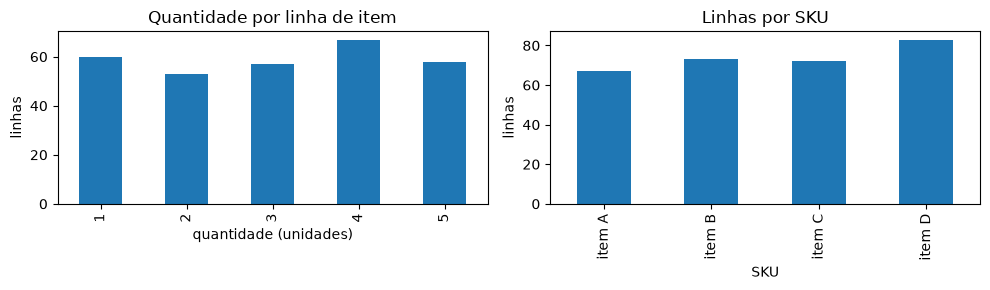

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
item['QUANTIDADE'].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(
    title='Quantidade por linha de item',
    xlabel='quantidade (unidades)',
    ylabel='linhas',
)
item['ID_ITEM'].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title='Linhas por SKU', xlabel='SKU', ylabel='linhas')
fig.tight_layout()
plt.show()

**Observação:** 295 linhas, sem nulos; `QUANTIDADE` inteira de 1 a 5, distribuída de forma parecida (53 a 67 linhas por valor); 67 a 83 linhas por SKU. 15 pares (pedido, SKU) repetidos (30 linhas); em 4 deles as quantidades são idênticas (8 linhas).

**Interpretação:** Os repetidos podem ser lançamentos duplicados ou compras legítimas; os dados não permitem distinguir (hipótese). A soma de quantidades segue a spec #1.

## Q3 — ITENS (cadastro)

In [5]:
print(sku_raw.to_string())
cadastro = con.sql('SELECT * FROM sku ORDER BY sku').df()
display(cadastro)
print(
    'SKU único:',
    cadastro['sku'].is_unique,
    '| valores positivos:',
    (cadastro['valor_unitario'] > 0).all(),
)

        0   1
0     NaN   0
1  item A  10
2  item B  15
3  item C  20
4  item D  25


,sku,valor_unitario
0,item A,10.00
1,item B,15.00
2,item C,20.00
3,item D,25.00


SKU único: True | valores positivos: True


**Observação:** 4 SKUs sem duplicidade, valores 10, 15, 20 e 25 (positivos). A primeira linha da planilha é um resquício (índice 0), não um dado. A planilha não tem cabeçalho e o PDF do case não diz o que ela representa. Os valores não coincidem com nenhuma quantidade da série (total vendido 211 a 251; maior venda diária 9 a 10; nenhum mês nem dia iguais ao valor).

**Interpretação (suposição, não confirmada):** a planilha é o valor unitário por SKU. A favor: progressão regular 10, 15, 20, 25 e a coluna VALOR_TOTAL em PEDIDO. Contra a hipótese de estoque: a venda acumulada passa do valor entre 06-06 e 06-18 sem reposição visível; a hipótese de estoque não é refutável com estes dados. Afeta apenas valores financeiros, não as quantidades das séries.

## Q4 — Integridade referencial e cardinalidade

In [6]:
checks = con.sql(
    'SELECT nome, ok, valor, detalhe FROM qualidade_verificacoes'
).df()
display(checks)

,nome,ok,valor,detalhe
0,Linhas por fonte,True,"pedido=181, item_pedido=295, sku=4",
1,Hash SHA-256 das planilhas,True,ver detalhe,pedido=8b8fdc84638e; item_pedido=e1a91536b9a1;...
2,Tipos fora do esperado,True,0,"ID, data, quantidade e valor unitário converte..."
3,ID_PEDIDO único em PEDIDO,True,181 pedidos,
4,ID_PEDIDO termina na data do pedido (AAAAMMDD),True,0,
5,Nulos em pedido.ID_PEDIDO,True,0/181,
6,Nulos em pedido.DATA,True,0/181,
7,Nulos em pedido.VALOR_TOTAL,False,181/181,coluna totalmente vazia; valor reconstruído do...
8,Nulos em item_pedido.ID_ITEM,True,0/295,
9,Nulos em item_pedido.QUANTIDADE,True,0/295,


In [7]:
print(
    con
    .sql("""
SELECT count(*) AS pedidos,
       count(*) FILTER (WHERE n_itens = 0) AS sem_itens
FROM (SELECT p.id_pedido, count(i.sku) AS n_itens
      FROM pedido p LEFT JOIN item_pedido i USING (id_pedido)
      GROUP BY p.id_pedido)
""")
    .df()
    .to_string()
)
print(
    con
    .sql("""
SELECT n_skus AS skus_distintos_no_pedido, count(*) AS pedidos
FROM (SELECT id_pedido, count(*) AS n_skus FROM item_pedido GROUP BY id_pedido)
GROUP BY ALL ORDER BY 1
""")
    .df()
    .to_string()
)

   pedidos  sem_itens
0      181          0
   skus_distintos_no_pedido  pedidos
0                         1      105
1                         2       55
2                         3       19
3                         4        2


**Observação:** Nenhum item sem pedido, nenhum item sem SKU, nenhum pedido sem item. 105 pedidos têm 1 SKU, 55 têm 2, 19 têm 3 e 2 têm 4.

**Interpretação:** Relação pedido 1:N item; item N:1 SKU. Integridade referencial completa.

## Q5 — Perda nos joins e soma de repetidos

In [8]:
print(
    con
    .sql("""
SELECT (SELECT count(*) FROM item_pedido) AS pares_apos_soma,
       (SELECT count(*) FROM base_consolidada) AS linhas_base,
       (SELECT sum(quantidade) FROM base_consolidada) AS quantidade_base
""")
    .df()
    .to_string()
)
print(
    'linhas brutas:',
    len(item),
    '| quantidade bruta:',
    item['QUANTIDADE'].sum(),
)
print('repetidos listados no relatório:', len(relatorio.itens_repetidos))

   pares_apos_soma  linhas_base  quantidade_base
0              280          280           895.00
linhas brutas: 295 | quantidade bruta: 895
repetidos listados no relatório: 15


**Observação:** 295 linhas viram 280 pares (pedido, SKU) e 280 linhas na base; 895 unidades antes e depois.

**Interpretação:** Não há perda nos joins; a soma dos repetidos preserva a quantidade.

## Q6 — Valor total do pedido reconstruído

VALOR_TOTAL original: nulos 181 / 181
count   181.00
mean     88.18
std      61.22
min      10.00
25%      45.00
50%      75.00
75%     110.00
max     385.00
soma total (R$): 15960.0


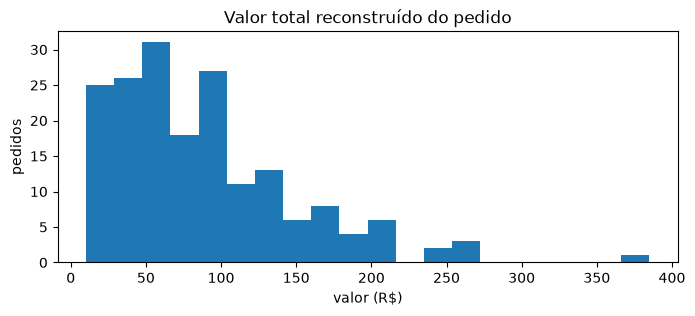

In [9]:
vt = con.sql('SELECT id_pedido, data, valor_total FROM pedido').df()
print(
    'VALOR_TOTAL original: nulos',
    pedido['VALOR_TOTAL'].isna().sum(),
    '/',
    len(pedido),
)
print(vt['valor_total'].describe().to_string())
print('soma total (R$):', vt['valor_total'].sum())
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(vt['valor_total'], bins=20)
ax.set(
    title='Valor total reconstruído do pedido',
    xlabel='valor (R$)',
    ylabel='pedidos',
)
plt.show()

**Observação:** VALOR_TOTAL original: 181/181 nulos. Reconstruído: mínimo 10, mediana 75, máximo 385, soma 15.960.

**Interpretação:** A reconstrução pela soma dos itens é possível e consistente com o cadastro; não há valor original para comparar.

## Q7 — Primeira venda e volume por SKU

In [10]:
resumo = con.sql("""
SELECT sku, min(data) AS primeira_venda
FROM base_consolidada GROUP BY sku ORDER BY sku
""").df()
display(resumo)

,sku,primeira_venda
0,item A,2021-06-01
1,item B,2021-06-04
2,item C,2021-06-01
3,item D,2021-06-04


**Observação:** Primeira venda: item A e item C em 2021-06-01; item B e item D em 2021-06-04.

**Interpretação:** Confirma o fato da Fase 0 e define o início do calendário de cada SKU (usado no #3).

## Séries diária e semanal — calendário e zeros imputados (ticket #3)

**Escopo:** só calendário e contagens (presença de pedidos por dia). Não se analisa a dinâmica das vendas por SKU (ticket #5, visão de desenvolvimento).

**Pergunta 8.** Os 12 dias sem nenhum pedido na rede se concentram em dias de baixa demanda ou formam blocos suspeitos? Isso valida a imputação de zeros?

**Hipóteses (nulas) para os testes de aleatorização:**
- H0-a: os 12 dias estão distribuídos ao acaso entre os 93 dias do histórico.
- H0-b: condicionada ao dia da semana (só segunda a quinta, os únicos dias em que ocorreram), a posição dos 12 dias é aleatória; mede se há blocos além do esperado.

Teste de aleatorização/permutação conforme Kutner et al. (2005), p. 714 (impresso), que também adverte que esses testes são conservadores em amostras pequenas. Premissa: sem ela, a escolha dos dias sob H0 é equiprovável; nenhuma outra distribuição é assumida. Todos os testes são **exploratórios** (12 eventos; escolhas feitas depois de ver os dados).

In [11]:
import math

import numpy as np

dias = con.sql("""
SELECT d::DATE AS data
FROM generate_series((SELECT min(data) FROM pedido),
                     (SELECT max(data) FROM pedido), INTERVAL 1 DAY) t(d)
""").df()
com_pedido = set(
    pd.to_datetime(con.sql('SELECT DISTINCT data FROM pedido').df()['data'])
)
dias['data'] = pd.to_datetime(dias['data'])
dias['sem_pedido'] = ~dias['data'].isin(com_pedido)
dias['dia_semana'] = dias['data'].dt.day_name()
dias['dow'] = dias['data'].dt.day_of_week
print(
    'dias no histórico:', len(dias), '| sem pedido:', dias['sem_pedido'].sum()
)
display(
    dias.loc[dias['sem_pedido'], ['data', 'dia_semana']].reset_index(drop=True)
)
por_dow = dias.groupby('dow').agg(
    dias=('sem_pedido', 'size'), sem_pedido=('sem_pedido', 'sum')
)
por_dow.index = ['seg', 'ter', 'qua', 'qui', 'sex', 'sab', 'dom']
display(por_dow)

dias no histórico: 93 | sem pedido: 12


,data,dia_semana
0,2021-06-02,Wednesday
1,2021-06-03,Thursday
2,2021-06-08,Tuesday
3,2021-06-16,Wednesday
4,2021-06-17,Thursday
5,2021-06-21,Monday
6,2021-06-24,Thursday
7,2021-08-02,Monday
8,2021-08-03,Tuesday
9,2021-08-04,Wednesday


,dias,sem_pedido
seg,13,3
ter,14,2
qua,14,4
qui,13,3
sex,13,0
sab,13,0
dom,13,0


In [12]:
# Blocos de dias consecutivos sem pedido
flags = dias['sem_pedido'].to_numpy()


def corridas(f):
    tamanhos, atual = [], 0
    for x in f:
        if x:
            atual += 1
        elif atual:
            tamanhos.append(atual)
            atual = 0
    if atual:
        tamanhos.append(atual)
    return tamanhos


obs = corridas(flags)
print('blocos (dias consecutivos):', obs, '| maior bloco:', max(obs))
dias['semana'] = dias['data'].dt.to_period('W-SUN').dt.start_time
print('dias sem pedido por semana (apenas semanas com ocorrência):')
print(dias[dias['sem_pedido']].groupby('semana').size().to_string())
print('dias sem pedido por mês:')
print(
    dias[dias['sem_pedido']]
    .groupby(dias['data'].dt.to_period('M'))
    .size()
    .to_string()
)

blocos (dias consecutivos): [2, 1, 2, 1, 1, 3, 1, 1] | maior bloco: 3
dias sem pedido por semana (apenas semanas com ocorrência):


semana
2021-05-31    2
2021-06-07    1
2021-06-14    2
2021-06-21    2
2021-08-02    3
2021-08-09    2
dias sem pedido por mês:
data
2021-06    7
2021-08    5
Freq: M


In [13]:
n, k = len(dias), int(dias['sem_pedido'].sum())
fds = dias['dow'].isin([4, 5, 6])
# Teste exato (hipergeométrico) de H0-a: nenhum dia cai de sex a dom
p_fds = math.comb(n - fds.sum(), k) / math.comb(n, k)
print(
    'dias sex-dom:',
    fds.sum(),
    '| sem pedido em sex-dom:',
    dias.loc[fds, 'sem_pedido'].sum(),
)
print(f'P(0 em sex-dom | H0-a) exato = {p_fds:.4f}')

rng = np.random.default_rng(20211030)
B = 100_000
# H0-a: bloco máximo e número de blocos sob posição aleatória entre os n dias
sim_a = [
    corridas(np.isin(np.arange(n), rng.choice(n, k, replace=False)))
    for _ in range(B)
]
# H0-b: posição aleatória restrita aos dias de segunda a quinta
elegivel = np.flatnonzero(~fds.to_numpy())
sim_b = [
    corridas(np.isin(np.arange(n), rng.choice(elegivel, k, replace=False)))
    for _ in range(B)
]
for nome, sim in (('H0-a', sim_a), ('H0-b (seg-qui)', sim_b)):
    maior = np.array([max(x) for x in sim])
    nblocos = np.array([len(x) for x in sim])
    p_maior = (maior >= max(obs)).mean()
    p_blocos = (nblocos <= len(obs)).mean()
    print(
        f'{nome}: P(maior bloco >= {max(obs)}) = {p_maior:.3f} | '
        f'P(nº de blocos <= {len(obs)}) = {p_blocos:.3f} | '
        f'média do maior bloco = {maior.mean():.2f}'
    )
# Julho sem nenhum dia sem pedido (observação post hoc)
JULHO = 7
jul = (dias['data'].dt.month == JULHO) & ~fds
print('seg-qui em julho:', int(jul.sum()), 'de', len(elegivel))
p_jul = math.comb(len(elegivel) - int(jul.sum()), k) / math.comb(
    len(elegivel), k
)
print(f'P(0 em julho | H0-b) exato = {p_jul:.4f}')

dias sex-dom: 39 | sem pedido em sex-dom: 0
P(0 em sex-dom | H0-a) exato = 0.0008


H0-a: P(maior bloco >= 3) = 0.135 | P(nº de blocos <= 8) = 0.032 | média do maior bloco = 1.95
H0-b (seg-qui): P(maior bloco >= 3) = 0.202 | P(nº de blocos <= 8) = 0.076 | média do maior bloco = 2.12
seg-qui em julho: 17 de 54
P(0 em julho | H0-b) exato = 0.0054


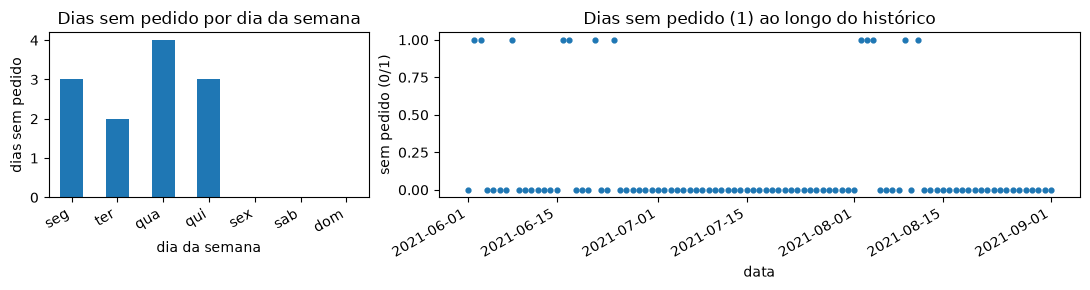

In [14]:
fig, axes = plt.subplots(
    1, 2, figsize=(11, 3), gridspec_kw={'width_ratios': [1, 2]}
)
por_dow['sem_pedido'].plot.bar(ax=axes[0])
axes[0].set(
    title='Dias sem pedido por dia da semana',
    xlabel='dia da semana',
    ylabel='dias sem pedido',
)
axes[1].scatter(dias['data'], dias['sem_pedido'].astype(int), s=12)
axes[1].set(
    title='Dias sem pedido (1) ao longo do histórico',
    xlabel='data',
    ylabel='sem pedido (0/1)',
)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [15]:
# Quantos dos 12 dias caem dentro do calendário de cada SKU
zeros = con.sql("""
SELECT sku, min(data) AS inicio_calendario, count(*) AS dias_calendario,
       sum(imputado::INT) AS zeros_imputados
FROM serie_diaria GROUP BY sku ORDER BY sku
""").df()
zeros['dias_sem_pedido_na_rede_no_calendario'] = [
    int(((dias['data'] >= pd.Timestamp(i)) & dias['sem_pedido']).sum())
    for i in zeros['inicio_calendario']
]
display(zeros)
semanais = con.sql("""
SELECT sku, min(semana) AS primeira, max(semana) AS ultima,
       count(*) AS semanas
FROM serie_semanal GROUP BY sku ORDER BY sku
""").df()
display(semanais)

,sku,inicio_calendario,dias_calendario,zeros_imputados,dias_sem_pedido_na_rede_no_calendario
0,item A,2021-06-01,93,36.00,12
1,item B,2021-06-04,90,35.00,10
2,item C,2021-06-01,93,40.00,12
3,item D,2021-06-04,90,27.00,10


,sku,primeira,ultima,semanas
0,item A,2021-06-07,2021-08-23,12
1,item B,2021-06-07,2021-08-23,12
2,item C,2021-06-07,2021-08-23,12
3,item D,2021-06-07,2021-08-23,12


**Observação:** os 12 dias sem pedido caem todos de segunda a quinta (0 em sexta a domingo; teste exato P = 0,0008 sob distribuição aleatória entre os 93 dias). Formam 8 blocos, o maior com 3 dias (08-02 a 08-04); sob posição aleatória entre segunda e quinta, P(maior bloco >= 3) = 0,20. Nenhum cai em julho (P = 0,005, achado post hoc). Os calendários têm 93 dias (A, C) e 90 dias (B, D); 12 e 10 desses dias sem pedido caem dentro deles. Cada SKU tem 12 semanas completas, de 2021-06-07 a 2021-08-23.

**Interpretação:** a imputação de zero nesses dias é plausível, pois eles caem em dias de menor presença de pedidos e não formam um bloco longo. Os dados não separam zero verdadeiro de dado perdido nem de ruptura; os 3 dias seguidos de agosto são os mais suspeitos e não podem ser verificados. Testes exploratórios (12 eventos), sem correção para múltiplas comparações.

**Limitação:** proporção de zeros imputados com o calendário do SKU: A 36/93 (39%), B 35/90 (39%), C 40/93 (43%), D 27/90 (30%), com o histórico completo (inclui o futuro OOT). O ADR 0003 cita 32% a 43%; o 32% corresponde ao D contado sobre 93 dias. Será recalculado na visão de desenvolvimento (#5).

## Resumo das observações

- A base consolidada relaciona pedido, item e SKU sem perda; o valor total do pedido foi reconstruído (R$ 15.960 no total).
- Os 15 pares repetidos foram somados e estão listados no relatório de qualidade.
- Fatos da Fase 0 reconferidos; dois refinados (índice de PEDIDO e prefixo do ID).

## Limitações

- 181 pedidos e 295 linhas; sem identificação de unidade nem estoque.
- O significado da planilha ITENS (valor unitário) é uma suposição: o PDF do case não o define.
- Esta seção audita estrutura e qualidade com o histórico completo; não analisa a dinâmica das séries (ticket #5, sobre a visão de desenvolvimento).

## Perguntas para o usuário

- Resposta do usuário em 2026-10-30: os pares repetidos (inclusive os de quantidades idênticas) **não** são duplicidade; as quantidades continuam somadas.
- Respondidas pelo usuário em 2026-10-30: mantém-se a suposição de que a planilha ITENS é o preço por unidade (afeta só valores financeiros); não há explicação operacional para os 3 dias seguidos sem pedido de 08-02 a 08-04, e eles não precisam de tratamento (permanecem como zeros imputados).